# Figure 3. Monthly solar PV export capacity by destination region

**Supporting questions:** How do monthly estimated exports of Panels, Cells and Wafers differ across destination regions in 2022–2025? Do regional peaks recur in the same calendar months?

**Audience:** Chinese solar PV exporters comparing the scale and timing of recorded destination-region trade flows.

**Interpretation:** summed product-stage capacity is not unique final-panel capacity or destination installed capacity. For a specific product's market, use the saved product-level monthly table rather than the combined total.


## 1. Read the saved analysis datasets



In [10]:
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

root = Path(".")
if not (root / "data").exists():
    root = Path("..")
processed = root / "data/Processed"
monthly = pd.read_csv(processed / "figure_3_monthly_region_capacity.csv")
summary = pd.read_csv(processed / "figure_3_annual_region_capacity_gw.csv")
robustness = pd.read_csv(processed / "figure_3_robustness_complete_coverage.csv")
peak_comparison = pd.read_csv(processed / "figure_3_peak_month_comparison.csv")
output = root / "Results/Fig3"
output.mkdir(parents=True, exist_ok=True)

## 2. Figure 3

One panel per year and one line per destination region. The horizontal axis is reporting month; the vertical axis is summed estimated monthly export capacity in GW equivalents. All panels use the same colors and vertical scale.

**Pattern:** Europe has the largest annual total in 2022; Asia leads in 2023–2025. Monthly peaks vary across years.

**Caption:** China's estimated monthly solar PV exports by recorded destination region, 2022–2025. Panels, Cells and Wafers are summed and converted from MW to GW equivalents. Regional and global aggregate rows are excluded. Missing destination-month-product records are not imputed.

**Limitation:** the three stages may represent related supply-chain flows; their sum does not measure unique final products or installed capacity. Four years do not establish stable seasonality.


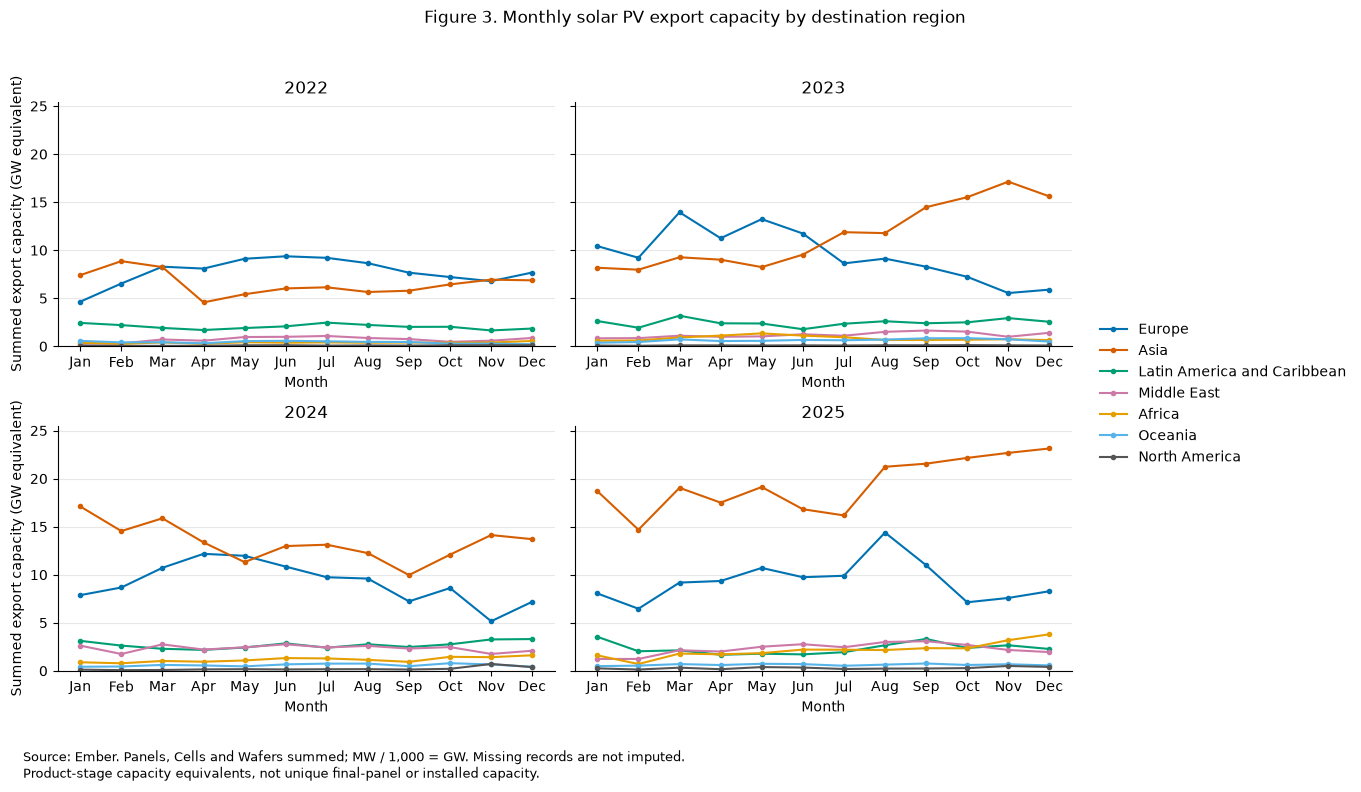

In [11]:
colors = {
    "Europe": "#0072B2",
    "Asia": "#D55E00",
    "Latin America and Caribbean": "#009E73",
    "Middle East": "#CC79A7",
    "Africa": "#E69F00",
    "Oceania": "#56B4E9",
    "North America": "#555555",
}
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharey=True)
for ax, year in zip(axes.flat, [2022, 2023, 2024, 2025]):
    for region in colors:
        data = monthly[(monthly["year"] == year) & (monthly["Region"] == region)]
        ax.plot(data["month"], data["Capacity (GW)"], color=colors[region],
                label=region, marker="o", markersize=3)
    ax.set_title(str(year))
    ax.set_xticks(range(1, 13), months)
    ax.set_ylim(0, monthly["Capacity (GW)"].max() * 1.1)
    ax.set_xlabel("Month")
    ax.grid(axis="y", alpha=0.3)
for ax in axes[:, 0]:
    ax.set_ylabel("Summed export capacity (GW equivalent)")
fig.suptitle("Figure 3. Monthly solar PV export capacity by destination region")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="center left", bbox_to_anchor=(0.78, 0.5), frameon=False)
fig.text(0.02, 0.02, "Source: Ember. Panels, Cells and Wafers summed; MW / 1,000 = GW. Missing records are not imputed.\n"
         "Product-stage capacity equivalents, not unique final-panel or installed capacity.", fontsize=9)
fig.tight_layout(rect=[0, 0.08, 0.78, 0.95])
fig.savefig(output / "Figure_3_Regional_Export_Capacity_2022_2025.png", dpi=250, bbox_inches="tight")
fig.savefig(output / "Figure_3_Regional_Export_Capacity_2022_2025.svg", bbox_inches="tight")
plt.show()

## 3. Summary table



In [12]:
display(summary.round(2))

,Region,2022 (GW),2023 (GW),2024 (GW),2025 (GW),Growth 2022–2025 (%)
0,Asia,78.34,138.58,160.42,232.80,197.17
1,Europe,93.20,114.51,109.76,111.74,19.88
2,Latin America and Caribbean,24.46,29.62,32.44,28.07,14.76
3,Middle East,8.43,14.22,28.17,27.21,222.60
4,Africa,4.58,10.00,13.88,25.89,465.29
5,Oceania,5.03,7.54,7.01,7.52,49.51
6,North America,1.00,1.12,2.49,3.44,243.46


## 4. Robustness comparison

The comparison table is read from `data/Processed/figure_3_robustness_complete_coverage.csv`. It compares all recorded observations with destination-product series present in all 48 months. The retained-capacity percentage uses each region's all-records 2025 total as its denominator.

The second table displays only region-years whose peak month changes. Month numbers run from 1 (January) to 12 (December).


In [13]:
display(robustness.round(2))
changed_peaks = peak_comparison[peak_comparison["peak_changed"]]
display(changed_peaks)

,Region,All records 2025 (GW),Complete coverage 2025 (GW),2025 capacity retained (%),All records growth 2022–2025 (%),Complete coverage growth 2022–2025 (%)
0,Asia,232.80,204.84,87.99,197.17,165.40
1,Europe,111.74,108.24,96.87,19.88,17.51
2,Latin America and Caribbean,28.07,26.06,92.86,14.76,8.39
3,Middle East,27.21,26.36,96.88,222.60,225.20
4,Africa,25.89,17.90,69.14,465.29,322.81
5,Oceania,7.52,7.40,98.49,49.51,48.55
6,North America,3.44,3.44,100.00,243.46,243.46


,year,Region,all_peak_month,complete_peak_month,peak_changed
22,2025,Asia,12,11,True


## 5. Three provisional findings

1. Asia's annual total rises from **78.34 GW equivalent in 2022 to 232.80 in 2025**. Europe leads in 2022; Asia leads in 2023–2025.
2. Africa rises from **4.58 to 25.89 GW equivalent**, a large increase from a smaller base.
3. Asia's peak month changes across years: February, November, January and December. Four years do not establish a fixed best export month.


In [14]:
display(peak_comparison.loc[peak_comparison["Region"] == "Asia", ["year", "all_peak_month"]])

,year,all_peak_month
1,2022,2
8,2023,11
15,2024,1
22,2025,12


## Interpretation of the robustness results

Asia and Europe remain the two largest regions in 2025 under both samples, and all seven regions retain positive growth from 2022. The full regional ranking does change: the Middle East and Latin America and Caribbean exchange third and fourth place. Asia's 2025 peak shifts from December to November; the other 27 region-year peak months remain unchanged.

The complete-coverage sample retains 90.29% of the main sample's combined 2025 capacity, but only 69.14% for Africa. Africa's 2022–2025 growth falls from 465.29% to 322.81%. The broad expansion remains visible, while the growth magnitude and close regional rankings depend on coverage.

Excluding incomplete destination-product series also removes real new or intermittent trade. The comparison is a sensitivity analysis, not a reason to replace the main sample or fill missing observations with zeros.

## Limitations

- `Capacity (MW)` is Ember's estimated capacity; product-specific estimation methods differ. In particular, panel and cell estimates use trade value and reference prices, so those capacity and value measures are mechanically related.
- Panels, cells and wafers are upstream and downstream stages. Their sum can reflect related supply-chain flows and is not unique final-panel or installed capacity.
- The recorded destination may be a re-export hub, rather than the location of final consumption.
- Totals sum available country-month-product records, whose coverage differs across destinations and products.
- Four years provide only four observations for each calendar month; this does not establish stable seasonality or an optimal shipment month.
- Capacity does not measure profit or attainable firm sales.
